In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sy
import pandas as pd
from scipy.optimize import minimize

# Introduction to Linear Regression and Linear Programming

**OBJECTIVES**

- Derive ordinary least squares models for data
- Evaluate regression models using mean squared error
- Examine errors and assumptions in least squares models
- Use `scikit-learn` to fit regression models to data
- Set up linear programming problems with constraints using `scipy.optimize`

## Calculus Refresher

An important idea is that of finding a maximum or minimum of a function.  From calculus, we have the tools required.  Specifically, a maximum or minimum value of a function $f$ occurs wherever $f'(x) = 0$ or is underfined.  Consider the function:

$$f(x) = x^2$$

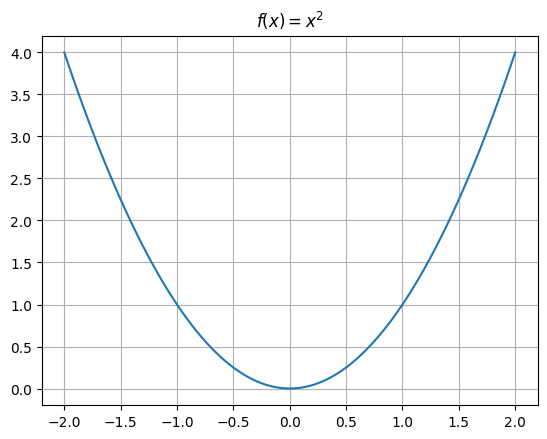

In [ ]:
def f(x): return x**2
x = np.linspace(-2, 2, 100)
plt.plot(x, f(x))
plt.grid()
plt.title(r'$f(x) = x^2$');

Here, using our power rule for derivatives of polynomials we have:

$$f'(x) = 2x$$

and are left to solve:

$$0 = 2x$$

or

$$x = 0$$

**PROBLEM**: Use `minimize` to determine where the function $f(x) = (5 - 2x)^2$ has a minimum.

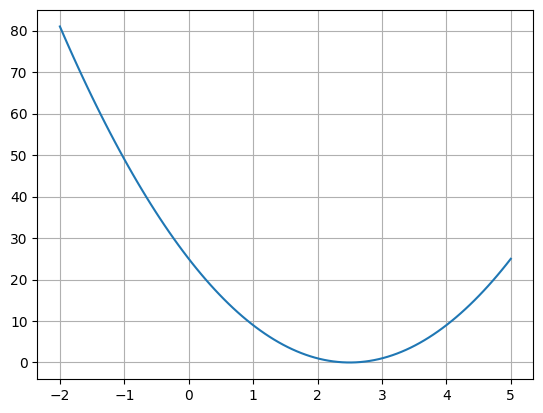

In [ ]:
def f(x): return (5 - 2*x)**2
x = np.linspace(-2, 5, 100)
plt.plot(x, f(x))
plt.grid();

In [ ]:
minimize?

In [ ]:
x0 = 0
results = minimize(f, x0 = x0)
print(results.x)

[2.49999999]


#### Using the chain rule

**Example 1**: Line of best fit

In [ ]:
import seaborn as sns

In [ ]:
tips = sns.load_dataset('tips')

In [ ]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


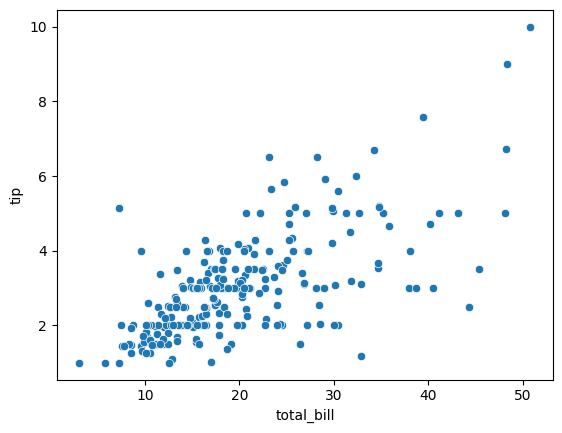

In [ ]:
sns.scatterplot(data = tips, x = 'total_bill', y = 'tip');

In [ ]:
def y1(x): return .19*x

In [ ]:
def y2(x): return .12*x

In [ ]:
x = tips['total_bill']

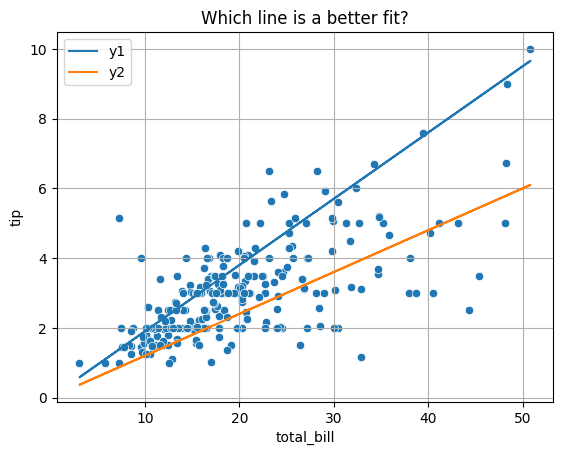

In [ ]:
plt.plot(x, y1(x), label = 'y1')
plt.plot(x, y2(x), label = 'y2')
plt.legend()
sns.scatterplot(data = tips, x = 'total_bill', y = 'tip')
plt.title('Which line is a better fit?')
plt.grid();

To decide between all possible lines we will examine the error in all these models and select the one that minimizes this error.

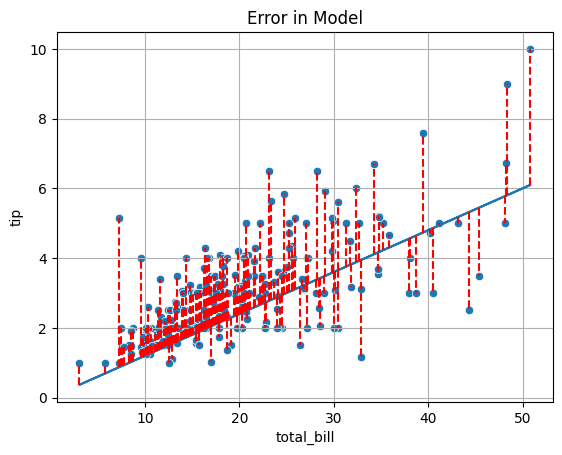

In [ ]:
plt.plot(x, y2(x))
for i, yhat in enumerate(y2(x)):
    plt.vlines(x = tips['total_bill'].iloc[i], ymin = yhat, ymax = tips['tip'].iloc[i], color = 'red', linestyle = '--')
sns.scatterplot(data = tips, x = 'total_bill', y = 'tip')
plt.title('Error in Model')
plt.grid();

#### Mean Squared Error

$$\text{MSE}(\beta_0) = \frac{1}{n}\sum_{i = 1}^n (y_i - \beta_0x)^2$$



**OBJECTIVE**: Minimize mean squared error

In [ ]:
def mse(beta):
    return np.mean((y - beta*x)**2)

In [ ]:
x = tips['total_bill']
y = tips['tip']

In [ ]:
mse(.17)

np.float64(1.502706427336066)

In [ ]:
for pct in np.linspace(.1, .2, 11):
    print(f'The MSE for slope {pct: .3f} is {mse(pct): .3f}')

The MSE for slope  0.100 is  2.078
The MSE for slope  0.110 is  1.713
The MSE for slope  0.120 is  1.443
The MSE for slope  0.130 is  1.267
The MSE for slope  0.140 is  1.185
The MSE for slope  0.150 is  1.197
The MSE for slope  0.160 is  1.303
The MSE for slope  0.170 is  1.503
The MSE for slope  0.180 is  1.797
The MSE for slope  0.190 is  2.185
The MSE for slope  0.200 is  2.667


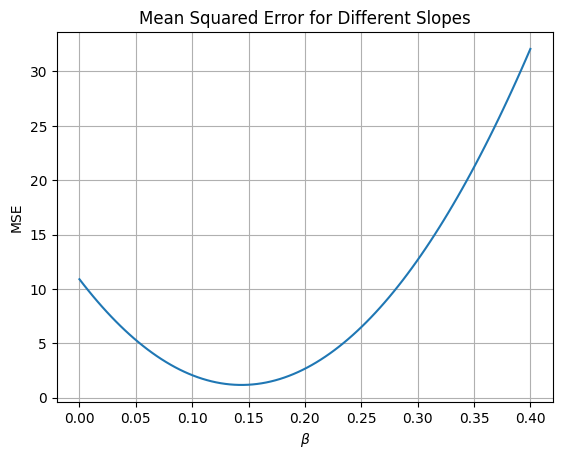

In [ ]:
betas = np.linspace(0, .4, 100)
plt.plot(betas, [mse(beta) for beta in betas])
plt.xlabel(r'$\beta$')
plt.ylabel('MSE')
plt.title('Mean Squared Error for Different Slopes')
plt.grid();

#### Using `scipy`

To find the minimum of our objective function, the `minimize` function from `scipy.optimize` is useful.  This relies on a variety of different optimization algorithms to find the minimum of a function.

In [ ]:
from scipy.optimize import minimize

In [ ]:
minimize(mse, .1 )

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 1.1781161154513358
        x: [ 1.437e-01]
      nit: 1
      jac: [ 1.103e-06]
 hess_inv: [[1]]
     nfev: 6
     njev: 3

### Solving the Problem Exactly

From calculus we know that the minimum value for a quadratic will occur where the first derivative equals zero.  Thus, to determine the equations for the line of best fit, we minimize the MSE function with respect to $\beta$.

$$f(\beta) = \frac{1}{n}\sum_{i = 1}^n (y - \beta x)^2$$

$$f'(\beta) = \frac{-2}{n}\sum_{i = 1}^n(y - \beta x) x$$

$$ 0 = \frac{-2}{n}\sum_{i = 1}^n(y - \beta x) x$$

$$0 = \sum_{i = 1}^n(y - \beta x) x$$

$$0 = \sum yx - \sum \beta x^2 $$

$$\sum \beta x^2 = \sum y x$$

$$\beta \sum x^2 = \sum y x$$

$$\beta = \frac{\sum y x}{\sum x^2}$$

In [ ]:
np.sum(tips['total_bill']*tips['tip'])/np.sum(tips['total_bill']**2)

np.float64(0.14373189527721666)

### Adding an intercept

Consider the model:

$$y = \beta_0 + \beta_1 x + \epsilon$$

where $\epsilon = N(0, 1)$.

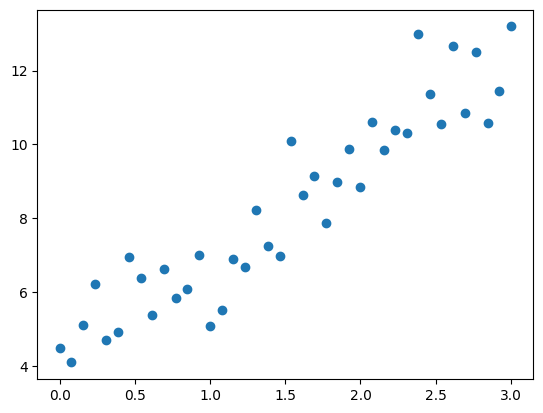

In [ ]:
np.random.seed(42)
x = np.linspace(0, 3, 40)
y = 3*x + 4 + np.random.normal(size = len(x))
plt.scatter(x, y)

Now, the objective function changes to be a function in 3-Dimensions where the slope and intercept terms are input and mean squared error is the output.

$$\text{MSE}(\beta_0, \beta_1) = \frac{1}{n}\sum_{i = 1}^n (y - (\beta_0 + \beta_1 x)^2)$$

In [ ]:
def mse(betas):
    return np.mean((y - (betas[0] + betas[1]*x))**2)

In [ ]:
mse([4, 3])

np.float64(0.9329508980248764)

In [ ]:
minimize(mse, [0, 0])

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 0.8296305032319822
        x: [ 4.179e+00  2.735e+00]
      nit: 7
      jac: [ 8.196e-08 -2.235e-08]
 hess_inv: [[ 1.921e+00 -9.483e-01]
            [-9.483e-01  6.327e-01]]
     nfev: 24
     njev: 8

In [ ]:
betas = minimize(mse, [0, 0]).x

In [ ]:
def lobf(x): return betas[0] + betas[1]*x

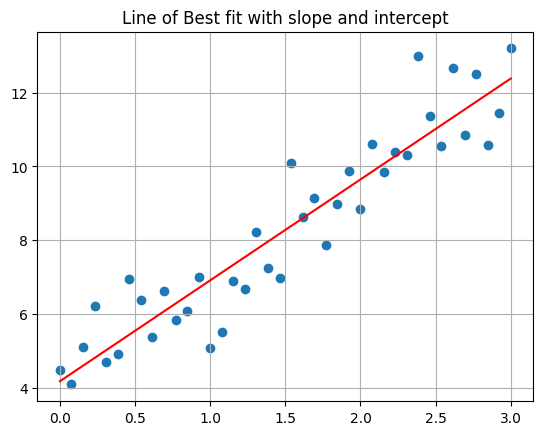

In [ ]:
plt.scatter(x, y)
plt.plot(x, lobf(x), color = 'red')
plt.grid()
plt.title('Line of Best fit with slope and intercept');

#### A second example

In [ ]:
import statsmodels.api as sm
duncan_prestige = sm.datasets.get_rdataset("Duncan", "carData")
print(duncan_prestige.__doc__)

.. container::

   .. container::

      ====== ===============
      Duncan R Documentation
      ====== ===============

      .. rubric:: Duncan's Occupational Prestige Data
         :name: duncans-occupational-prestige-data

      .. rubric:: Description
         :name: description

      The ``Duncan`` data frame has 45 rows and 4 columns. Data on the
      prestige and other characteristics of 45 U. S. occupations in
      1950.

      .. rubric:: Usage
         :name: usage

      .. code:: R

         Duncan

      .. rubric:: Format
         :name: format

      This data frame contains the following columns:

      type
         Type of occupation. A factor with the following levels:
         ``prof``, professional and managerial; ``wc``, white-collar;
         ``bc``, blue-collar.

      income
         Percentage of occupational incumbents in the 1950 US Census who
         earned $3,500 or more per year (about $36,000 in 2017 US
         dollars).

      education
        

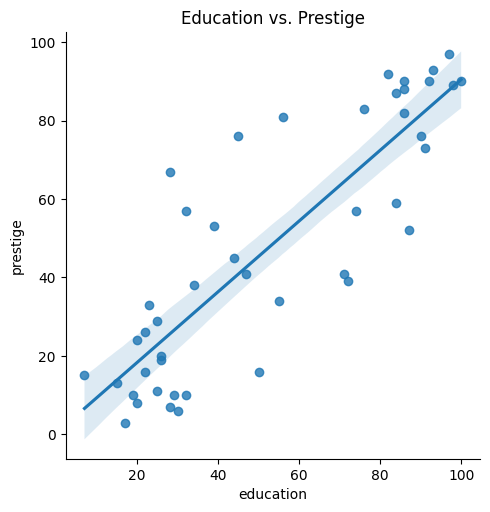

In [ ]:
sns.lmplot(duncan_prestige.data, x = 'education', y = 'prestige')
plt.title('Education vs. Prestige');

- Fit a model with an intercept to the data.  
- What is the slope of the line and what does this mean in terms of education and income?
- What is the intercept of the model and what does this mean in terms of education and income?

In [ ]:
duncan_prestige.data.head()

,type,income,education,prestige
rownames,,,,
accountant,prof,62,86,82
pilot,prof,72,76,83
architect,prof,75,92,90
author,prof,55,90,76
chemist,prof,64,86,90


In [ ]:
x = duncan_prestige.data[['education']]
y = duncan_prestige.data['prestige']

In [ ]:
x.shape

(45, 1)

In [ ]:
# !pip install -U scikit-learn

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
model = LinearRegression() #instantiate -- step 1

In [ ]:
model.fit(x, y) #fit it on our data

LinearRegression()

In [ ]:
predictions = model.predict(x)
predictions

array([77.85563665, 68.83567885, 83.26761134, 81.46361978, 77.85563665,
       76.05164509, 84.16960712, 90.48357758, 78.75763243, 77.85563665,
       67.03168729, 88.67958602, 87.77759024, 76.05164509, 82.36561556,
       30.95185608, 40.87380966, 50.79576324, 39.97181388, 74.24765353,
       65.22769573, 49.89376746, 64.32569995, 45.38378856, 21.02990249,
       35.46183498, 25.53988139, 29.14786452, 20.12790671, 22.83389405,
       26.44187717,  6.59797001, 23.73588983, 17.42191937, 13.81393625,
       18.32391515, 23.73588983, 25.53988139, 15.61792781, 20.12790671,
       27.34387295, 22.83389405, 18.32391515, 42.67780122, 29.14786452])

In [ ]:
model.coef_, model.intercept_

(array([0.90199578]), np.float64(0.2839995438216505))

In [ ]:
model.coef_[0]

np.float64(0.5458339094008801)

#### Examining Errors in the Model

Once we have a model, it is important to examine the properties of the residuals.  Specifically, we aim to examine the residuals for patterns in error and the overall distribution of these errors.

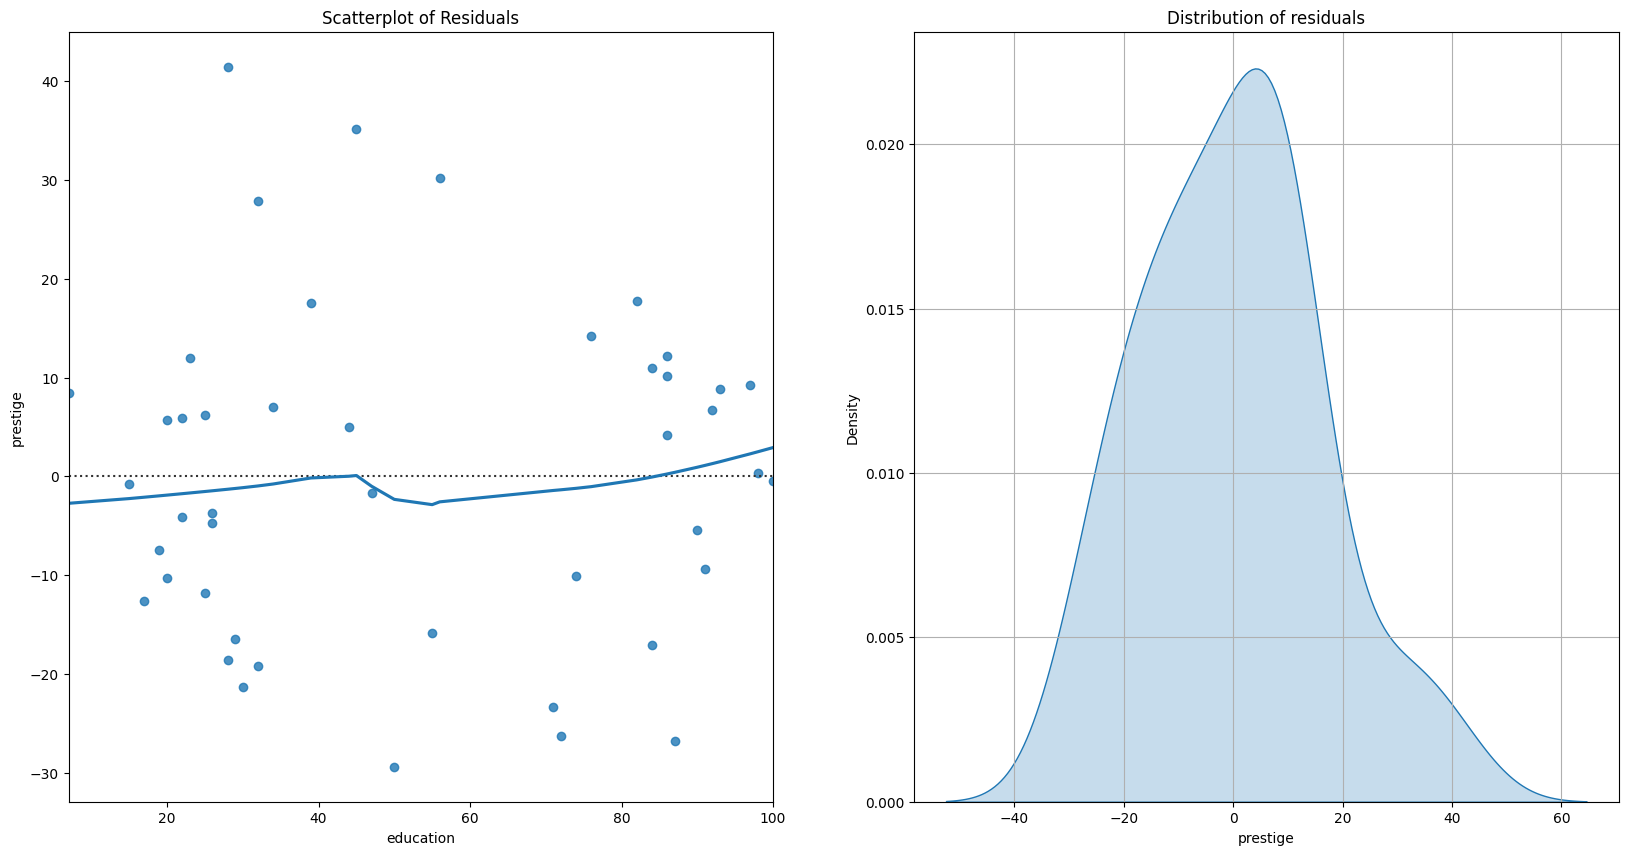

In [ ]:
fig, ax = plt.subplots(1, 2, figsize = (20, 10))
sns.residplot(x = x, y = y, ax = ax[0], lowess=True)
ax[0].set_title('Scatterplot of Residuals')
sns.kdeplot((y - (model.intercept_ + model.coef_[0]*x.values[:, 0])), ax = ax[1], fill = True);
ax[1].grid()
ax[1].set_title('Distribution of residuals');

### Using `scikit-learn`

The `scikit-learn` library has many predictive models and modeling tools.  It is a popular library in industry for Machine Learning tasks. [docs](https://scikit-learn.org/stable/index.html)

In [ ]:
# !pip install -U scikit-learn

In [ ]:
credit = pd.read_csv('https://raw.githubusercontent.com/jfkoehler/nyu_bootcamp_fa25/refs/heads/main/data/Credit.csv', index_col=0)
credit.head()

,Income,Limit,Rating,Cards,Age,Education,Gender,Student,Married,Ethnicity,Balance
1,14.891,3606,283,2,34,11,Male,No,Yes,Caucasian,333
2,106.025,6645,483,3,82,15,Female,Yes,Yes,Asian,903
3,104.593,7075,514,4,71,11,Male,No,No,Asian,580
4,148.924,9504,681,3,36,11,Female,No,No,Asian,964
5,55.882,4897,357,2,68,16,Male,No,Yes,Caucasian,331


In [ ]:
from sklearn.linear_model import LinearRegression

**PROBLEM**: Which feature is the strongest predictor of `Balance` in the data?

<Axes: >

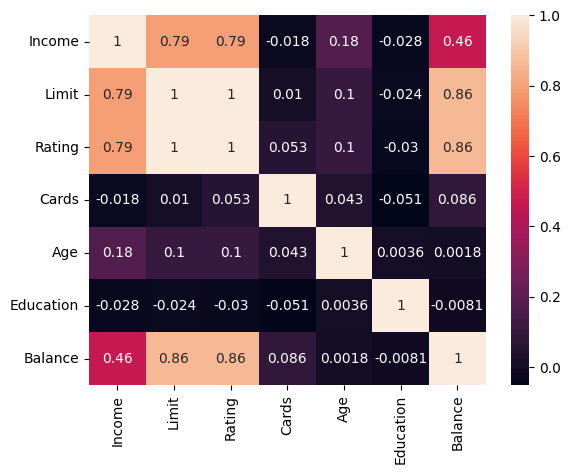

In [ ]:
sns.heatmap(credit.corr(numeric_only = True), annot = True)

In [ ]:
X = credit[['Rating']]
y = credit['Balance']

**PROBLEM**: Build a `LinearRegression` model, determine the **Root Mean Squared Error** and interpret the slope and intercept.

1. Instantiate
2. Fit
3. Predict/score

In [ ]:
credit_model = LinearRegression()

In [ ]:
credit_model.fit(X, y)

LinearRegression()

In [ ]:
yhat = credit_model.predict(X)

In [ ]:
print(f'The model is y = {credit_model.coef_[0]}x + {credit_model.intercept_}')

The model is y = 2.5662403273433196x + -390.84634178723786


(array([  3.,  11.,  31.,  91., 116.,  86.,  41.,   9.,   6.,   6.]),
 array([-712.2825064 , -558.1506416 , -404.01877679, -249.88691199,
         -95.75504718,   58.37681762,  212.50868243,  366.64054724,
         520.77241204,  674.90427685,  829.03614165]),
 <BarContainer object of 10 artists>)

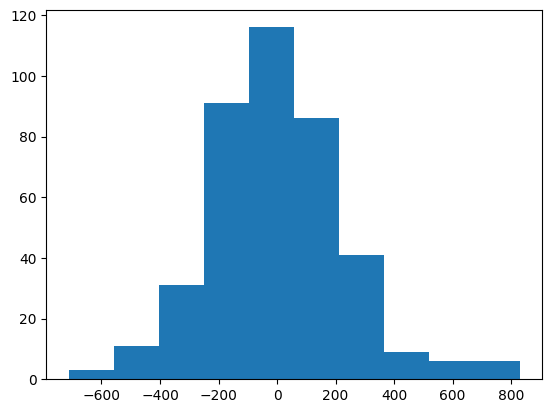

In [ ]:
plt.hist(y - yhat)

In [ ]:
from sklearn.metrics import mean_squared_error

In [ ]:
yhat

array([ 335.39967085,  848.64773632,  928.20118647, 1356.76332113,
        525.30145507, 1069.34440447,  273.80990299,  923.06870581,
        291.77358529,  869.17765894, 1120.66921102,  -36.70517661,
        620.25234719,  920.50246549,  299.47230627,  122.40172368,
        343.09839183,  479.10912918,  758.82932486,  838.38277501,
        212.22013514,  784.49172814,  155.76284794,  630.5173085 ,
          9.48714928,  445.74800493,  350.79711281,  463.71168722,
       2044.51572886,  663.87843275,  669.01091341,  148.06412695,
       1053.94696251,   24.88459124,  119.83548335,  173.72653023,
        776.79300715,  794.75668945,  379.02575642,  286.64110463,
        258.41246103,  989.79095432,  509.90401311,  751.13060388,
        812.72037174, 1056.51320283,  574.06002129,  430.35056296,
        135.23292532,  517.60273409,  574.06002129,  381.59199674,
        620.25234719,  669.01091341,  -36.70517661,    4.35466862,
        563.79505998,  550.96385835,  330.2671902 ,  609.98738

In [ ]:
#error between true and predicted
np.sqrt(mean_squared_error(y, yhat))

np.float64(231.4903995457098)

### Problem: Determine $\alpha$ and $\beta$ of an investment

Consider an investment with return of the market as $R_M$ (say the S&P) and the return of a stock $R$ over the same time period.

$$R = \alpha + \beta*R_M + \epsilon$$

In [ ]:
import yfinance as yf

In [ ]:
data = yf.download(["NVDA", "SPY"], period="5y")
data.head()

/tmp/ipython-input-2940777676.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(["NVDA", "SPY"], period="5y")
[*********************100%***********************]  2 of 2 completed


Price           Close                   High                    Low  \
Ticker           NVDA         SPY       NVDA         SPY       NVDA   
Date                                                                  
2020-10-16  13.769464  323.764832  14.078521  326.990446  13.750522   
2020-10-19  13.456672  318.842590  13.940943  325.666719  13.365948   
2020-10-20  13.603971  320.119690  13.757751  323.382602  13.465892   
2020-10-21  13.483590  319.513733  13.749529  322.254582  13.436484   
2020-10-22  13.320338  321.266479  13.570325  321.853809  13.191481   

Price                        Open                 Volume            
Ticker             SPY       NVDA         SPY       NVDA       SPY  
Date                                                                
2020-10-16  323.587700  13.994029  325.321691  242392000  89501900  
2020-10-19  317.938296  13.860688  325.032789  298068000  68425600  
2020-10-20  319.429826  13.542159  320.194258  229212000  60051900  
2020-10-21  319.206071  13.583535  320.073067  219596000  63575000  
2020-10-22  317.574734  13.481347  319.728254  290480000  55399300

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1256 entries, 2020-10-16 to 2025-10-16
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, NVDA)   1256 non-null   float64
 1   (Close, SPY)    1256 non-null   float64
 2   (High, NVDA)    1256 non-null   float64
 3   (High, SPY)     1256 non-null   float64
 4   (Low, NVDA)     1256 non-null   float64
 5   (Low, SPY)      1256 non-null   float64
 6   (Open, NVDA)    1256 non-null   float64
 7   (Open, SPY)     1256 non-null   float64
 8   (Volume, NVDA)  1256 non-null   int64  
 9   (Volume, SPY)   1256 non-null   int64  
dtypes: float64(8), int64(2)
memory usage: 107.9 KB


In [ ]:
close = data.iloc[:, [0, 1]]

<Axes: xlabel='Date'>

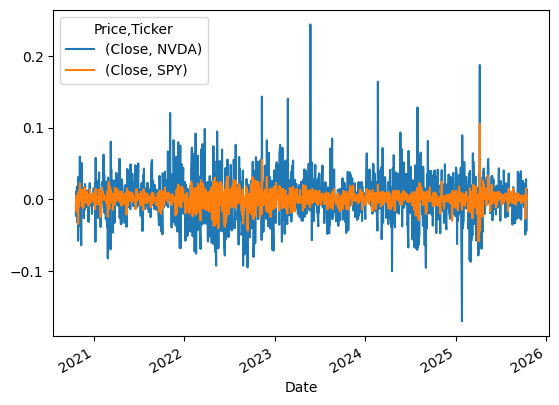

In [ ]:
close.pct_change().plot()

In [ ]:
returns = close.pct_change()

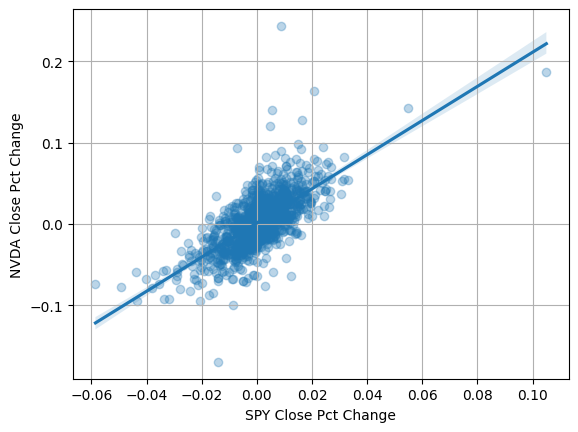

In [ ]:
sns.regplot(x = returns.iloc[:, 1], y = returns.iloc[:, 0], scatter_kws={'alpha': 0.3})
plt.xlabel('SPY Close Pct Change')
plt.ylabel('NVDA Close Pct Change')
plt.grid();

In [ ]:
returns.head(2)

Price          Close          
Ticker          NVDA       SPY
Date                          
2020-10-16       NaN       NaN
2020-10-19 -0.022716 -0.015203

In [ ]:
#instantiate
returns.dropna(inplace = True)
X = returns.iloc[:, [1]]
y = returns.iloc[:, [0]]
model = LinearRegression()

In [ ]:
#fit
model.fit(X, y)

LinearRegression()

In [ ]:
#examine our alpha and beta
alpha = model.intercept_
beta = model.coef_
print(alpha, beta)

[0.00126425] [[2.10015821]]


### Linear Programming: An example

A dog daycare feeds the dogs a diet that requires a minimum of 15 grams of fiber, 30 grams of protein.  Each pound of chick peas contains 1 gram of protein, 5 grams of fiber, and 25 grams of fat. Cottage cheese contains 2 grams of protein, 1 gram of fiber, and 14 grams of fat. Suppose that chick peas are priced at 8 USD per pound, and cottage cheese at 6 USD per pound.  The nutritionist claims the dogs will not eat more than 285 grams of fat.   Your goal is to obtain the most economical solution given these constraints.

This is summarized in the table below:

| ingredient | protein | fiber | fat | cost |
| ------ | ------ | ------- | ------- | ------- |
| chick peas | 1 g | 5 g | 25 g | \$8 |
| cottage cheese | 2 g | 1 g | 14 g | \$6 |
| minimum | 15 g | 30 g |  |   |
| maximum |    |     |  285 g |   |

Mathematically, the objective function is:

$$C = 6x + 8y$$

where $x$ = chick peas and $y$ = cottage cheese.  This is the total cost of the combination of chick peas and cottage cheese.

We will save the coefficients as a list for use later.

In [ ]:
c = [6, 8]

Because each pound of chick peas contains 1 gram of protein and each cottage cheese 2 grams, and know this needs to combine to at least 15 grams you have:

$$2x + y \geq 15$$

As for cottage cheese, you have:

$$x + 5y \geq 30$$

As for the fat content, you have:

$$14x + 25y \leq 285$$

Further, the amount of $x$ and $y$ must not be negative.

#### Graphical representation

To visualize the solution, you can imagine each of the constraints as a region.  First, functions for these are defined and plotted together.  


In [ ]:
def cp(x): #chick peas
    return -2*x + 15
def cc(x): #cottage cheese
    return -1/5*x + 30/5
def fat(x): #fat
    return -14/25*x + 285/25
y = 0
x = np.linspace(0, 30, 100)

In [ ]:
d = np.linspace(0, 30, 1000)
x, y = np.meshgrid(d, d)
plt.imshow((y > cp(x)) & (y < fat(x)) & (y > cc(x)).astype('int'),
           origin = 'lower',
          cmap = 'Greys',
          extent=(x.min(), x.max(), y.min(), y.max()),
          alpha = 0.4)
plt.plot(d, cc(d), '-', color = 'black', label = 'cottage cheese')

plt.plot(d, cp(d), '-', color = 'blue', label = 'chick peas')

plt.plot(d, fat(d), '-', color = 'red', label = 'fat')
plt.ylim(0, 15)
plt.xlim(0, 20)
plt.title('Feasible region for dog food problem')
plt.grid();

The form of all solutions can be found by rewriting the objective function as:

$$y = -\frac{6}{8}x + \frac{C}{8}$$

Below, different values of $C$ are plotted against the original region.  Note that the objective function will obtain its maximum and minimum values at the vertices of the polygon.  Hence, to solve the problem, you need only look to the vertices.  These are highlighted in the plot on the right.

In [ ]:
# fig, ax = plt.subplots(1, 2, figsize = (30, 10))
for i in range(10, 1000, 10):
    plt.plot(d, -6/8*d + i/8, '--', color = 'black')
plt.plot(d, -6/8*d + i, '--', color = 'black', label = 'slopes of -6/8 + c/8')
d = np.linspace(0, 30, 1000)
x, y = np.meshgrid(d, d)
plt.imshow((y > cp(x)) & (y < fat(x)) & (y > cc(x)).astype('int'),
           origin = 'lower',
          cmap = 'Greys',
          extent=(x.min(), x.max(), y.min(), y.max()),
          alpha = 0.4)
plt.plot(d, cc(d), '-', color = 'black', label = 'cottage cheese')

plt.plot(d, cp(d), '-', color = 'blue', label = 'chick peas')

plt.plot(d, fat(d), '-', color = 'red', label = 'fat')
plt.ylim(0, 15)
plt.xlim(0, 20)
plt.title('Feasible region for dog food problem\nwith possible cost lines')
plt.grid()
plt.legend();

In [ ]:
d = np.linspace(0, 30, 1000)
x, y = np.meshgrid(d, d)
plt.imshow((y > cp(x)) & (y < fat(x)) & (y > cc(x)).astype('int'),
           origin = 'lower',
          cmap = 'Greys',
          extent=(x.min(), x.max(), y.min(), y.max()),
          alpha = 0.4)
plt.plot(d, cc(d), '-', color = 'black', label = 'cottage cheese')
plt.plot(15, 3, 'ro', label = 'possible solutions')
plt.plot(d, cp(d), '-', color = 'blue', label = 'chick peas')
plt.plot(d, fat(d), '-', color = 'red', label = 'fat')
plt.ylim(0, 15)
plt.xlim(0, 20)
plt.title('Feasible region for dog food problem')
plt.grid()
plt.plot(5, 5, 'ro')
plt.plot(5/2, 10, 'ro')
plt.legend();

#### using `linprog`

To solve the problem using python, `scipy.optimize` contains the `linprog` function that will solve this problem.  The one exception is that the greater than inequality constraints need to be converted to less thans by multiplying both sides by -1.  

$$C = 6x + 8y$$
$$2x + y \geq 15$$
$$x + 5y \geq 30$$
$$14x + 25y \leq 285$$

In [ ]:
#cost coeffients
c = [6, 8]
#coefficients of less than problems
A = [[-2, -1], [-1, -5], [14, 25]]
#right side of inequalities
b = [-15, -30, 285]
res = optim.linprog(c, A, b)

In [ ]:
res

**EXAMPLE**

Suppose we have the opportunity to invest in four projects with given cash flows, net present value, and profitability index ($\frac{NPV}{\text{investment}}$) given below.

| PROJECT | $C_0$ | $C_1$ | $C_2$ | NPV at 10% | Profitability Index |
| ------- | ------ | ------- | ------- | -------- | --------- |
| A | -10 | -30 | 5 | 21 | 2.1 |
| B | -5 | 5 | 2 | 16 | 3.2 |
| C | -5 | 5 | 15 | 12 | 2.4 |
| D | 0 | -40 | 60 | 13 | 0.4 |



$$NPV = 21x_A + 16x_B + 12x_C + 13x_D$$

**CONSTRAINTS**

Cash flows for period 0 must not be greater than 10 million.

$$10x_A + 5x_B + 5x_C + 0x_D \leq 10$$

Total outflow in period 1 must not be greater than 10 million.

$$-30x_A - 5x_B - 5x_C + 40x_D \leq 10$$

Finally the amount of the investment must be positive and we cannot purchase more than one of each.

$$0 \leq x_A \leq 1$$
$$0 \leq x_B \leq 1$$
$$0 \leq x_C \leq 1$$
$$0 \leq x_D \leq 1$$

In [ ]:
from scipy.optimize import linprog

In [ ]:
coefs = [-21, -16, -12, -13]
constr = [[10, 5, 5, 0],
          [-30, -5, -5, 40]]
right_side = [10, 10]
bounds = [(0, 1), (0, 1), (0, 1), (0, 1)]

In [ ]:
linprog(coefs, constr, right_side, bounds = bounds)